# **Online Advertising Performance Marketing**

## Objectives

* I have used the Online Advertising Performance Dataset again because I believe I can present the visual data clearly in Tableau or Power BI. As the task in this unit is to clean the data, present our findings and make notes as I go along.

* I will also include a Machine Learning algorithm to either present the discovered data or possibly make a prediction.

* Present the new found data in a dashboard with considerations of the GDPR guidlines, as I don't want to present a persons details e.g. place of living, medical requirements and finance.

## Inputs & Outputs

* This time not only have I asked Chatgpt and Copliot to fix or generate codes, but I have commented in the sections of the markdowns what I wanted the output to be, Copilot has read it and has predicted the codes used to get the results.

* Cleaning the dataset was interesting as I found two unnamed columns with missing values, I knew of these columns from the previous project AND there still no documentation for Campaign 2. So for the sake of this task to use Machine Learning to make a prediction, I removed Campaign 2.

* Thanks to commenting in the code dropdowns, I was able to define what I wanted for the Machine Learning to predict in the charts. However I did ask Chatgpt the same requests as it was able to perform quicker than Copilot in VSCode when wanting predicting code. This was either wait for Copilot to autofill OR ask Chatgpt to generate that code, although Copilot knew what I was working with, that also made coding easier with the 'Fix' option and this made very little editing from Chatgpt's code. 

## Additional Comments

I have used the Online Advertising Perfomance Data created by N. Aniruddhan from Kaggle.

I have also Credited N. Aniruddhan in the description of the dataset in Tableau.

https://public.tableau.com/views/Unit2ResOnlineAdvPerformance/Dashboard1?:language=en-GB&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link

---

# Work directory

In [1]:
import os
current_dir = os.getcwd()
current_dir

'c:\\Users\\PC\\Documents\\vs_code\\Unit2_resub_Online_Advertising\\Unit2_Resub_Online_Advertising_Performance\\jupyter_notebooks'

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [3]:
current_dir = os.getcwd()
current_dir

'c:\\Users\\PC\\Documents\\vs_code\\Unit2_resub_Online_Advertising\\Unit2_Resub_Online_Advertising_Performance'

# Section 1

Imports & Machine Learning algorithms.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Import after installation
import sklearn
print(sklearn.__version__)

1.9.1


In [6]:
sklearn_version = sklearn.__version__
print(f"Scikit-learn version: {sklearn_version}")

Scikit-learn version: 1.9.1


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Machine Learning concepts + Algorthims

The concepts of Machine Learning inlcude Probability, Statistics and Data Analysis.

* Probability = The chance of the outcome, e.g. I flip a coin and want Heads, 50/50 chance

* Statistics = The process of collecting, summarising, analysing and interpreting the data, e.g. discovering the mean, median and mode. Alongside variation, sampling and statistical inference.

* Data Analysis = The process of turning raw data into useful information to answer or solve problems. So the idea is, we collect the raw data, then clean it and search for patterns or trends and unusual values. Visualise with charts or graphs in a dashboard to communicate our findings and explain why we chode to act on those decisions to back up the evidence or results.

These are the types of learning for AI and what they are commonly used for.

* Supervised = The AI learns from examples that are already correct and known.

Used for: Predicting house prices, detecting spam, forecasting sales.

* Unsupervised = AI discovers groups, relathionships and structures without being given the correct answer.

Used for: Customer segmentation, anomaly detection, discovering patterns in datasets.

* Reinforcement = AI takes action, revises their conseuence and re-evaluates with a strategy to gain a reward. 

Used for: Robotics, game-playing, resource allocation, control systems.

* Semi-Supervised = AI learns from a small set of labelled examples and larger sets of unlabelled examples.

Used for: Image classification, speech recognition, medical image analysis.

* Self-Supervised = AI generates it's own targets from the input data rather than human/user interaction.

Used for: Large language models, image understanding, speech processing.

After asking Chatgpt for the ML (Machine Learning) types, it has also asked me if I wanted a suggestion. I know with the dataset I have chosen I'm aiming towards a predictive outcome/algorithm because I think it would be interesting to see how the campaigns WOULD have been in an extra month or two.

Chatgpt Recommends:
* Linear Regression 
* Random Forest Regressor
* Gradient boosting: XGBoost, LightGBM, CatBoost
* Ridge & Lasso Regression
* K-Nearest Neighbours Regression (KNN)

---

# Section 2

Loading the dataset, investigating Campaign 2 and removing missing values.

In [8]:
from pathlib import Path
import pandas as pd

# read 'online_advertising_performance_data.csv' from the 'datasets' folder
# Try the real dataset names and common project locations.
project_root = Path.cwd()
candidate_files = [
    project_root / "datasets" / "online_advertising_performance_data.csv",
    project_root / "datasets" / "OAP_CGPT_data_cleaned.csv",
    project_root.parent / "datasets" / "online_advertising_performance_data.csv",
    project_root.parent / "datasets" / "OAP_CGPT_data_cleaned.csv",
    Path(r"c:/Users/PC/Documents/vs_code/Unit2_resub_Online_Advertising/Unit2_Resub_Online_Advertising_Performance/datasets/OAP_CGPT_data_cleaned.csv"),
    Path(r"c:/Users/PC/Documents/vs_code/Unit2_resub_Online_Advertising/datasets/OAP_CGPT_data_cleaned.csv"),
]

data_path = next((p for p in candidate_files if p.exists()), candidate_files[0])

df = pd.read_csv(data_path)
df.head()
df.head()

,month,day,campaign_number,user_engagement,banner,placement,displays,cost,clicks,revenue,post_click_conversions,post_click_sales_amount,Unnamed: 12,Unnamed: 13
0,April,1,camp 1,High,160 x 600,abc,4,0.0060,0,0.0000,0,0.0000,NaN,NaN
1,April,1,camp 1,High,160 x 600,def,20170,26.7824,158,28.9717,23,1972.4602,NaN,NaN
2,April,1,camp 1,High,160 x 600,ghi,14701,27.6304,158,28.9771,78,2497.2636,NaN,NaN
3,April,1,camp 1,High,160 x 600,mno,171259,216.8750,1796,329.4518,617,24625.3234,NaN,NaN
4,April,1,camp 1,Low,160 x 600,def,552,0.0670,1,0.1834,0,0.0000,NaN,NaN


As I know already this is the same dataset/csv file from the previous unit. I can see Unnamed 12 & 13 with missing values, But I still wonder if Campaign 2 has any values or documentation after April?

Thinking ahead, I asked Chatgpt to inspect and clean the dataset for any Duplicates, Missing Values and reoprt any edits or findings. 

In [9]:
# from datasets folder, read 'OAP_CGPT_data_cleaned.csv'
df = pd.read_csv(data_path)
df.head()

,month,day,campaign_number,user_engagement,banner,placement,displays,cost,clicks,revenue,post_click_conversions,post_click_sales_amount,Unnamed: 12,Unnamed: 13
0,April,1,camp 1,High,160 x 600,abc,4,0.0060,0,0.0000,0,0.0000,NaN,NaN
1,April,1,camp 1,High,160 x 600,def,20170,26.7824,158,28.9717,23,1972.4602,NaN,NaN
2,April,1,camp 1,High,160 x 600,ghi,14701,27.6304,158,28.9771,78,2497.2636,NaN,NaN
3,April,1,camp 1,High,160 x 600,mno,171259,216.8750,1796,329.4518,617,24625.3234,NaN,NaN
4,April,1,camp 1,Low,160 x 600,def,552,0.0670,1,0.1834,0,0.0000,NaN,NaN


Chatgpt has removed Unnamed 12 & 13, great. I aslo asked if theres further documentation for Campaign 2 past April, same answer as before except "No, The cleaned CSV contains no documentation for Campaign 2 beyond April." 

In the Data Wrangler I can see 'camp 2'. My thoughts are now 'Do I make a prediction for Camp 2 when there's no further information to possibly predict, even past April from the original dataset?' and for the sake of a business enquiry 'Do I present Campaigns 1 & 3 with their prediction of an extra month (Or two)?

In [10]:
# read 'OAP_CGPT_data_without_camp2.csv' from the path already located
df = pd.read_csv(data_path)
df.head()

,month,day,campaign_number,user_engagement,banner,placement,displays,cost,clicks,revenue,post_click_conversions,post_click_sales_amount,Unnamed: 12,Unnamed: 13
0,April,1,camp 1,High,160 x 600,abc,4,0.0060,0,0.0000,0,0.0000,NaN,NaN
1,April,1,camp 1,High,160 x 600,def,20170,26.7824,158,28.9717,23,1972.4602,NaN,NaN
2,April,1,camp 1,High,160 x 600,ghi,14701,27.6304,158,28.9771,78,2497.2636,NaN,NaN
3,April,1,camp 1,High,160 x 600,mno,171259,216.8750,1796,329.4518,617,24625.3234,NaN,NaN
4,April,1,camp 1,Low,160 x 600,def,552,0.0670,1,0.1834,0,0.0000,NaN,NaN


I have proceeded without Campaign 2 due to no further information.

Also asking Chatgpt to remove Campaign 2, with a report of changes and accuracy(?). I feel that if I asked/commented Copilot to remove Camp 2, would it just remove the name from the 'campaign_number'?

Having looked again in Data Wrangler, I can see campaigns 1 & 3, the 12 columns that Chatgpt said it HAS NOT removed, Missing & or duplicate Values and unnamed columns have been successfully removed.

# Problems

* After trying to rename and save the 'OAP_CGPT_without_camp2' I have had a glorious set back. The code markdowns where I simply comment '#read X from Datasets folder' doesn't work, however I noticed Copilot (?) has made a csv path.

* Future problem. I have asked Chatgpt about making filters in Tableau, as I would like to add 'Current' & 'Prediction' filters. Chatgpt's answer is yes but I'm better using the Desktop (app) version than Public (web browser). As a student I knew I would be limited with a free version of a software, in another project I attempted to upload Desktop to Public but to no success. I will figure something out to present my findings.

# Machine Learning - Predictions



Historical monthly totals:
        clicks  post_click_conversions
month                                 
April  1661125                  252075
May     539904                  234425
June    291808                  165268

Predicted totals for July:
                            July
clicks                       0.0
post_click_conversions  130449.0


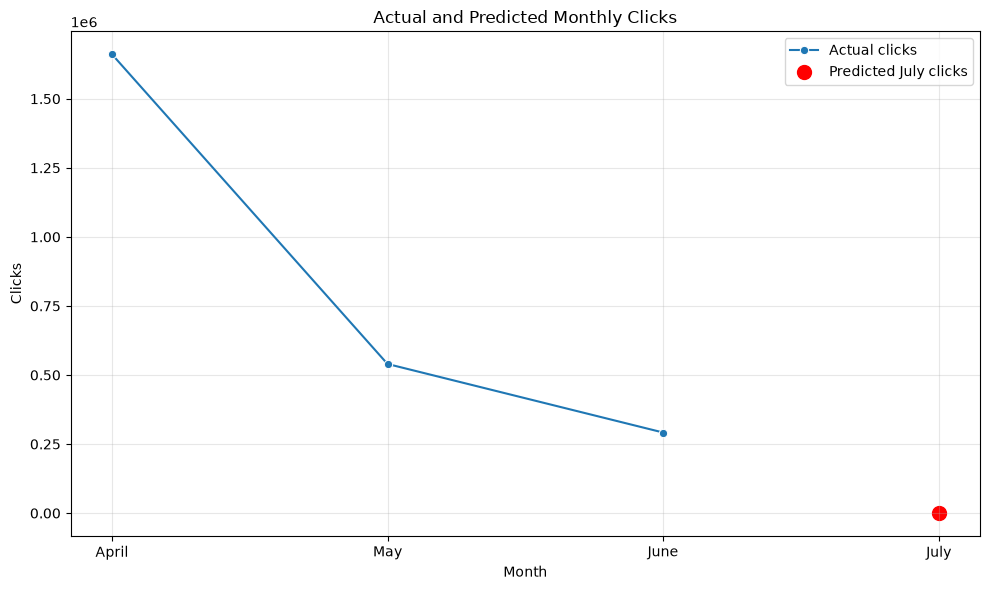

In [11]:
# 1. Load your dataset
#df = pd.read_csv("OAP_CGPT_data_without_camp2.csv")
# find 'OAP_CGPT_data_without_camp2.csv' in the datasets folder
df = pd.read_csv(data_path)

# 2. Define the correct month order
month_order = ["April", "May", "June"]
df["month"] = pd.Categorical(
    df["month"], categories=month_order, ordered=True
)

# 3. Calculate monthly totals
metrics = [
    "clicks",
    "post_click_conversions",
]

monthly = df.groupby("month", observed=False)[metrics].sum()

print("Historical monthly totals:")
print(monthly)

# 4. Train a model and predict July
X = [[1], [2], [3]]
next_month = [[4]]

predictions = {}

for metric in metrics:
    model = LinearRegression()
    model.fit(X, monthly[metric].values)

    # Prevent negative predictions for these metrics
    forecast = model.predict(next_month)[0]
    predictions[metric] = max(0, forecast)

# 5. Display the July forecast
forecast_df = pd.DataFrame(
    [predictions], index=["July"]
)

print("\nPredicted totals for July:")
print(forecast_df.round(2).T)

# 6. Plot historical revenue and July forecast
plot_data = monthly[["clicks"]].reset_index()
plot_data["month"] = plot_data["month"].astype(str)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=plot_data,
    x="month",
    y="clicks",
    marker="o",
    label="Actual clicks"
)

plt.scatter(
    ["July"],
    [predictions["clicks"]],
    color="red",
    s=100,
    label="Predicted July clicks"
)

plt.title("Actual and Predicted Monthly Clicks")
plt.xlabel("Month")
plt.ylabel("Clicks")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

After asking Chatgpt for codes that would predict an extra month for this dataset (OAP_CGPT_data_without_camp2) I can see that the red dot is the predicted outcome and decline of clicks, to me this looks an accurate result for July. In the previous unit/assignment I could see those declines on the generate charts.

I believe the prediction has worked, alongside adding the extra month (July). However I'm not sure if this chart represents the monthly clicks for singular or both campaigns (1&3). I wonder if the prediction will be better designed and presented in Tableau with it's forecasting feature.

# Tableau

https://public.tableau.com/views/Unit2ResOnlineAdvPerformance/Dashboard1?:language=en-GB&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link

Moving over to Tableau, I have been able to experiment with graphs and charts to present my findings, however due to limitations I cannot add a prediction or use Tableau's forecast feature.

Comparing the predicted chart in this notebook to the charts in Tableau, I can see the decline in PCC and Clicks. Again as I mentioned before and is now answered. The chart in the notebook hasn't been given a campaign to look at, so it is my understanding that the prediction has used Clicks from both campaigns. I will attempt to make predictions for each campaign.

I have also decided to present a Line & Bar chart for curiosity, to see which one would be more appealing. Thinking now a bar chart represents a more definite reading, however a line presents a passing/flow of time, be it declining or rising. 

In [12]:
#predict clicks and post_click_conversions for July using a linear regression model based on historical data from April, May, and June. The predictions are displayed in a DataFrame and visualized in a line plot with actual clicks and predicted July clicks highlighted. for camp 1 and camp 3.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import calendar

# 1. Load your uploaded dataset
# Load the dataset from the known project path and fall back to the known candidates
data_file = data_path if hasattr(data_path, "exists") and data_path.exists() else None

if data_file is None:
    for p in candidate_files:
        if p.exists():
            data_file = p
            break

if data_file is None:
    raise FileNotFoundError(
        "Dataset not found. Please ensure the CSV is in the project folder or update the file path."
    )

df = pd.read_csv(data_file)

# 2. Convert the month and day columns into dates
# The year is set to 2025 because your dataset has no year column.
# This is used only to establish the chronological order.
month_numbers = {
    "April": 4,
    "May": 5,
    "June": 6
}

df["month_num"] = df["month"].map(month_numbers)

df["Date"] = pd.to_datetime({
    "year": 2025,
    "month": df["month_num"],
    "day": df["day"]
})

# 3. Select the campaigns and metrics
campaigns = ["camp 1", "camp 3"]

metrics = [
    "clicks",
    "post_click_conversions"
]

# 4. Aggregate all rows into daily campaign totals
daily = (
    df[df["campaign_number"].isin(campaigns)]
    .groupby(["campaign_number", "Date"])[metrics]
    .sum()
    .reset_index()
)

# 5. Set the forecast month to July 2025
forecast_year = 2025
forecast_month = 7

days_in_month = calendar.monthrange(
    forecast_year, forecast_month
)[1]

forecast_dates = pd.date_range(
    start=f"{forecast_year}-{forecast_month:02d}-01",
    periods=days_in_month,
    freq="D"
)

results = []

# 6. Train a separate model for each campaign and metric
for campaign in campaigns:
    campaign_data = (
        daily[daily["campaign_number"] == campaign]
        .set_index("Date")
        .sort_index()
    )

    for metric in metrics:
        # Fill any missing dates with zero activity
        series = campaign_data[metric].asfreq("D", fill_value=0)

        # Create a continuous time index
        X = np.arange(len(series)).reshape(-1, 1)
        y = series.values

        # Train linear regression
        model = LinearRegression()
        model.fit(X, y)

        # Predict daily values for July
        future_X = np.arange(
            len(series),
            len(series) + days_in_month
        ).reshape(-1, 1)

        daily_predictions = model.predict(future_X)

        # Counts cannot be negative
        daily_predictions = np.maximum(
            daily_predictions, 0
        )

        # Sum daily forecasts to get the monthly forecast
        monthly_prediction = round(
            daily_predictions.sum()
        )

        results.append({
            "Campaign": campaign,
            "Metric": metric,
            "Forecast Month": "July 2025",
            "Predicted Monthly Total": monthly_prediction
        })

# 7. Display the four predictions
forecast_df = pd.DataFrame(results)

print("\nNEXT MONTH'S CAMPAIGN FORECAST")
print(forecast_df.to_string(index=False))

# 8. Save predictions
forecast_df.to_csv(
    "campaign_1_and_3_forecast.csv",
    index=False
)

print("\nForecast saved to campaign_1_and_3_forecast.csv")



NEXT MONTH'S CAMPAIGN FORECAST
Campaign                 Metric Forecast Month  Predicted Monthly Total
  camp 1                 clicks      July 2025                    36150
  camp 1 post_click_conversions      July 2025                   134635
  camp 3                 clicks      July 2025                    37767
  camp 3 post_click_conversions      July 2025                     1780

Forecast saved to campaign_1_and_3_forecast.csv


I have asked Chatgpt to generate codes for future predictions for PCC and Clicks for Campaigns 1 & 3 for an extra month (July).

In [13]:
# show me 'campaign_1_and_3_forecast.csv' 
pd.read_csv('campaign_1_and_3_forecast.csv')
df_forecast = pd.read_csv('campaign_1_and_3_forecast.csv')
display(df_forecast)

,Campaign,Metric,Forecast Month,Predicted Monthly Total
0,camp 1,clicks,July 2025,36150
1,camp 1,post_click_conversions,July 2025,134635
2,camp 3,clicks,July 2025,37767
3,camp 3,post_click_conversions,July 2025,1780


This dataset looks good, at least what I am aiming to concentrate on (PCC & Clicks). I wonder if saving this new csv file will work? as previous I have had a few set backs.

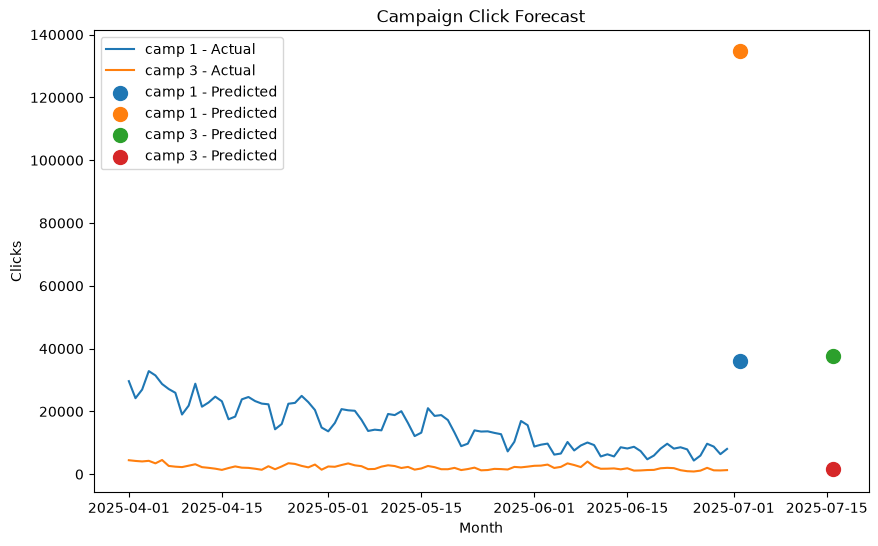

In [14]:
#generate a line plot showing actual clicks for April, May, and June, and predicted clicks for July for both campaigns. The x-axis should represent the months, and the y-axis should represent the number of clicks. Use different colors or markers to distinguish between actual and predicted values.
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot actual clicks for April, May, and June
for campaign in campaigns:
    campaign_data = (
        daily[daily["campaign_number"] == campaign]
        .set_index("Date")
        .sort_index()
    )
    plt.plot(campaign_data.index, campaign_data["clicks"], label=f"{campaign} - Actual")

# Plot predicted clicks for July
for _, row in df_forecast.iterrows():
    if row["Forecast Month"] == "July 2025":
        plt.scatter(
            pd.to_datetime("2025-07-01") + pd.Timedelta(days=1 if row["Campaign"] == "camp 1" else 15),
            row["Predicted Monthly Total"],
            label=f"{row['Campaign']} - Predicted",
            s=100
        )

plt.xlabel("Month")
plt.ylabel("Clicks")
plt.title("Campaign Click Forecast")
plt.legend()
plt.show()

I noticed in this prediction/chart has predicted PCC & Clicks but hasn't labelled them, although I do find the prediction itself so off. There's three predictions that I would argue the success of, because in previous iterations (Even in Tableau) we see an individual lines declining, the closest prediction that might be more accurate than the three is Camp 3 - Predicted (Red dot) as we have seen a steady flow of PCC.

---

# Conclusions & Next Steps

* I think organising was imperative and made the workflow easier. Such as having a folder for the datasets, as it made the workspace more organised and Copilot was able to autofill the required code to use the csv files.

* With the Machine Learning's prediction, I did enjoy looking at the first iteration but I knew from looking at the titles of the columns that when prompting Copilot it did not predict each campaign but possibly (& believe) Clicks in general. The second iteration did include each campaign, PCC, Clicks and July! I know I used Chatgpt to generate codes and I did read at the end of the request "These are estimates, not guaranteed results, and three months of history provide limited evidence for longer-term trends." So this was a consideration when asking for a prediction as my understanding is, the result will not always be accurate. I do wonder where the infromation come from to get three predictions higher on the table?

* I will definatley be looking more into Tableau's features, as I belive the forecasting would have been not just interesting to learn but also a bit more accurate than what I've presented in the notebook.

* I will also be looking into Power BI or Streamlit's prediction power, out of curiosity and if the interface is just as manageable, if I do decide to present the data to a business standard.

* In Tableau, I know one of the goals is to research the User Engagment in this project. I will need to do more experimenting as the values were "High, Medium or Low" because I have tried in Tableau to make a table/chart/graph, the UE has had a column with PCC & Clicks almost intertwined between April & June. If it is because the UE has verbal values then next time I will find not just a simple chart or graph but a solution to better present that research.